<a href="https://colab.research.google.com/github/MLILA05/COU07506-labs/blob/main/Copy_of_COU07506_Week01_240242422800.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Task 1.3 — Working with audio

# Week 1 — Lab 0: Setting Up the DSP Laboratory

- Name:DAUDI MUSA MLILA
- Registration number:240242422800
- Date:24/11/2026
- Group:7

## Pre-lab question
Three devices I used today and one signal each processes:

1.Smartphone
2.Desktop
3.mike

## Task 1.1 — Elementary sequences

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

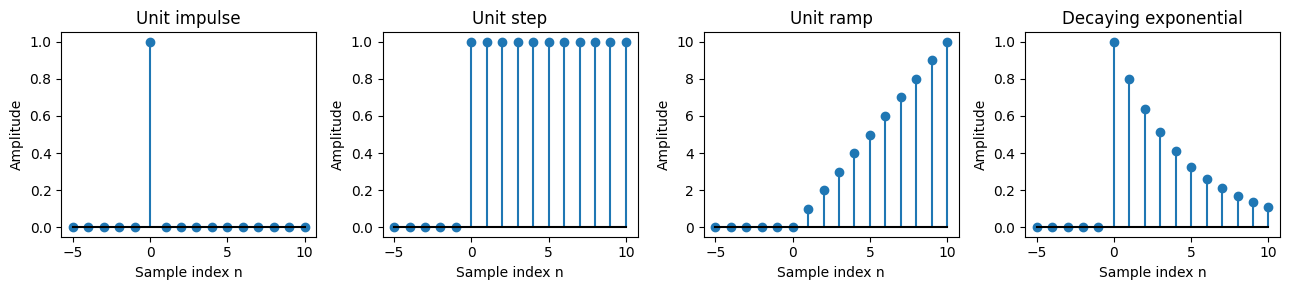

In [ ]:
n = np.arange(-5, 11)

delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 3))

for ax, values, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["Unit impulse", "Unit step", "Unit ramp", "Decaying exponential"],
):
    ax.stem(n, values, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

## Task 1.2 — Change the parameters

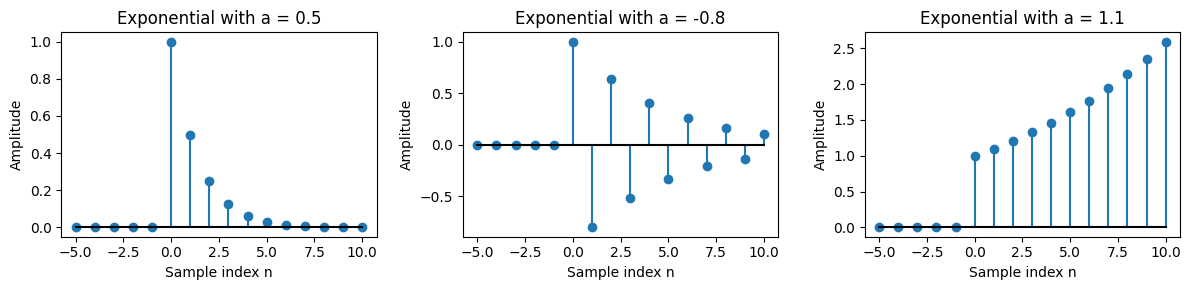

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    x = a**n * step
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"Exponential with a = {a}")
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

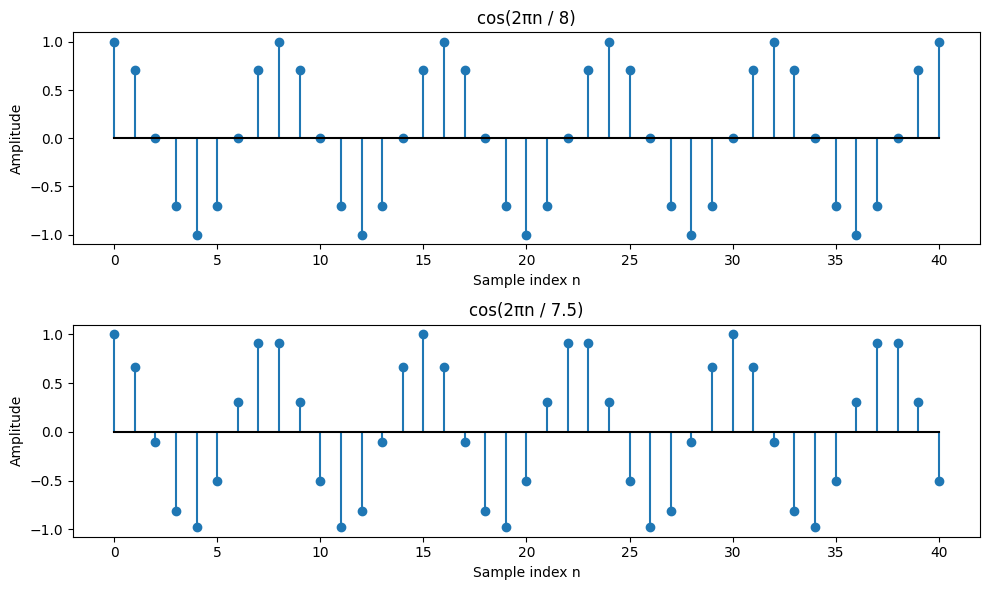

In [ ]:
n_cos = np.arange(41)
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

for ax, divisor in zip(axes, [8, 7.5]):
    x = np.cos(2 * np.pi * n_cos / divisor)
    ax.stem(n_cos, x, basefmt="k-")
    ax.set_title(f"cos(2πn / {divisor})")
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

## Task 1.3 — Working with audio

Sampling rate = 48,000 Hz
Duration = 4.00 s
Number of samples = 192,000


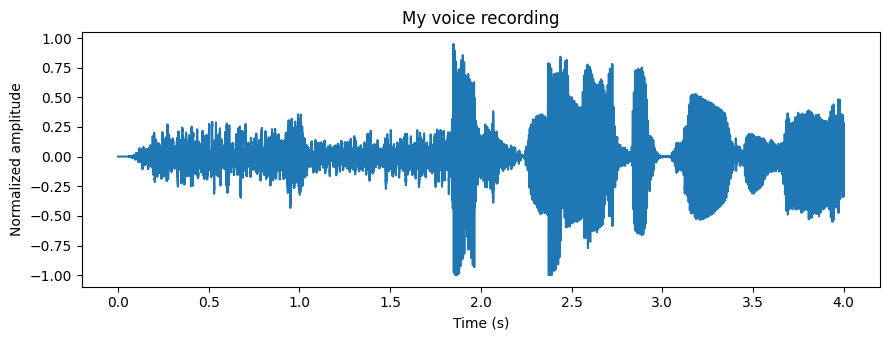

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, display
from scipy.io import wavfile

# Find the uploaded WAV file.
audio_path = Path("/my_voice.wav")
if not audio_path.is_file():
    audio_path = Path("/content/my_voice.wav")

if not audio_path.is_file():
    raise FileNotFoundError("Upload my_voice.wav using the Colab Files panel.")

# Read the sampling rate and audio samples.
fs, recording = wavfile.read(audio_path)
recording = recording[:4 * fs]  # Keep the first 4 seconds
x = recording.astype(float)


# Centre unsigned 8-bit audio at zero, if applicable.
if recording.dtype == np.uint8:
    x -= 128

# Convert stereo audio to mono by averaging the channels.
if x.ndim == 2:
    x = x.mean(axis=1)

# Scale the peak amplitude to 1, unless the recording is silent.
peak = np.max(np.abs(x))
if peak > 0:
    x = x / peak

# Calculate the duration and the time of each sample.
num_samples = len(x)
duration = num_samples / fs
t = np.arange(num_samples) / fs

print(f"Sampling rate = {fs:,} Hz")
print(f"Duration = {duration:.2f} s")
print(f"Number of samples = {num_samples:,}")

plt.figure(figsize=(9, 3.5))
plt.plot(t, x)
plt.title("My voice recording")
plt.xlabel("Time (s)")
plt.ylabel("Normalized amplitude")
plt.tight_layout()
plt.show()

display(Audio(x, rate=fs, normalize=False))

Analysis Questions


1. My recording has a sampling rate of 48,000 Hz. Mono audio stores one number per sample, so one minute needs numbers.

2. A stem plot shows the value of at each integer sample index. A continuous line connects the points and can suggest that the signal has values between the samples.

3. The growing exponential would violate bounded-input, bounded-output (BIBO) stability if it were the impulse response of a discrete-time LTI system. The sum of its absolute values is infinite, so even a bounded input such as a unit step would produce an output that grows without bound.
